In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
BASE_DIR = '/content/drive/MyDrive/Explainable AI/XAI_project'
SEED = 42
CLASS_MAP = {'negative': 0, 'neutral': 1, 'positive': 2}

In [3]:
import os
import re
import json
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sys

import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay,roc_auc_score, roc_curve, auc

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

Using device: cuda


In [4]:
module_path = os.path.abspath(os.path.join(BASE_DIR, 'utils'))

if module_path not in sys.path:
    sys.path.append(module_path)

import dataset_handler as ds

# Datasets initialization

In [5]:
r1_train = ds.load_dataset(os.path.join(BASE_DIR, ds.LOCAL_DIR_R1_TRAIN), labels=ds.TERNARY_LABELS)
r2_train = ds.load_dataset(os.path.join(BASE_DIR, ds.LOCAL_DIR_R2_TRAIN), labels=ds.TERNARY_LABELS)

df_train = ds.create_df(r1_train, r2_train)
df_train['enc_label'] = df_train['label'].map(CLASS_MAP)

In [6]:
r1_val = ds.load_dataset(os.path.join(BASE_DIR, ds.LOCAL_DIR_R1_VAL),  labels=ds.TERNARY_LABELS)
r2_val = ds.load_dataset(os.path.join(BASE_DIR, ds.LOCAL_DIR_R2_VAL), labels=ds.TERNARY_LABELS)

df_val = ds.create_df(r1_val, r2_val)
df_val['enc_label'] = df_val['label'].map(CLASS_MAP)

In [7]:
r1_test = ds.load_dataset(os.path.join(BASE_DIR, ds.LOCAL_DIR_R1_TEST),  labels=ds.TERNARY_LABELS)
r2_test = ds.load_dataset(os.path.join(BASE_DIR, ds.LOCAL_DIR_R2_TEST), labels=ds.TERNARY_LABELS)

df_test = ds.create_df(r1_test, r2_test)

# Encode dataset target according to model classes
df_test['enc_label'] = df_test['label'].map(CLASS_MAP)

#  Baseline

In [8]:
# Load model
# I decided to use roberta trained for sentiment analysis (3 classes) on twitter dataset
# Classes are {0: 'negative', 1: 'neutral', 2: 'positive'}
MODEL_NAME = 'cardiffnlp/twitter-roberta-base-sentiment-latest'
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME)
model.to(device)
model.eval()

print(f"Model '{MODEL_NAME}' loaded on {device}.")
print(f"Model label mapping: {model.config.id2label}")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/929 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  501MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base-sentiment-latest
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.bias   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Model 'cardiffnlp/twitter-roberta-base-sentiment-latest' loaded on cuda.
Model label mapping: {0: 'negative', 1: 'neutral', 2: 'positive'}


model.safetensors: reconstructing file:   0%|          |  0.00B /  501MB            

model.safetensors: downloading bytes:           |  0.00B            

Overall Accuracy : 0.6516
Overall Macro-F1 : 0.6495

              precision    recall  f1-score   support

    negative       0.72      0.55      0.62      1440
     neutral       0.56      0.82      0.67      1440
    positive       0.75      0.59      0.66      1440

    accuracy                           0.65      4320
   macro avg       0.68      0.65      0.65      4320
weighted avg       0.68      0.65      0.65      4320

Round 1 -> Accuracy: 0.6611 | Macro-F1: 0.6594


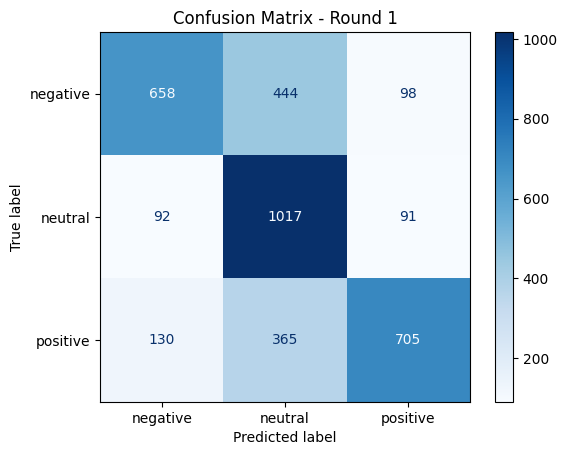

Round 2 -> Accuracy: 0.6042 | Macro-F1: 0.6030


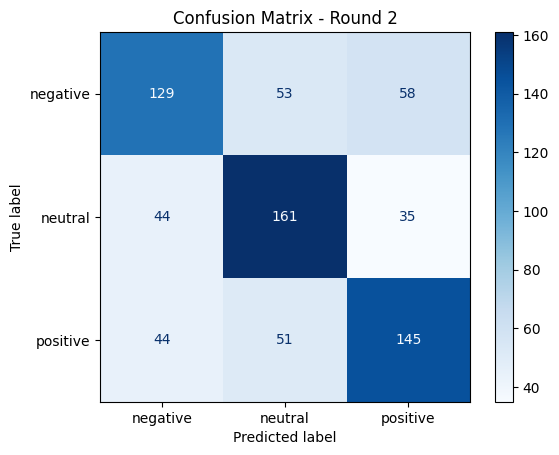

In [9]:
texts = df_test["text"].tolist()
labels = df_test["enc_label"].to_numpy()
rounds = df_test["round"].to_numpy()

batch_size = 64
all_logits, all_preds = [], []

with torch.no_grad():
    for i in range(0, len(texts), batch_size):
        batch_texts = texts[i : i + batch_size]
        enc = tokenizer(
            batch_texts,
            padding=True,
            truncation=True,
            max_length=128,
            return_tensors="pt",
        ).to(device)

        logits = model(**enc).logits.cpu().numpy()
        all_logits.append(logits)
        all_preds.append(logits.argmax(axis=-1))

logits = np.vstack(all_logits)
preds = np.concatenate(all_preds)

print(f"Overall Accuracy : {accuracy_score(labels, preds):.4f}")
print(f"Overall Macro-F1 : {f1_score(labels, preds, average='macro'):.4f}\n")
print(
    classification_report(
        labels, preds, target_names=[model.config.id2label[i] for i in range(3)]
    )
)

for r in sorted(np.unique(rounds)):
    mask = rounds == r
    print(
        f"Round {r} -> Accuracy: {accuracy_score(labels[mask], preds[mask]):.4f} | "
        f"Macro-F1: {f1_score(labels[mask], preds[mask], average='macro'):.4f}"        
    )
    cm = confusion_matrix(labels[mask], preds[mask], labels=[0, 1, 2])
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm, display_labels=[model.config.id2label[i] for i in range(3)]
    )
    disp.plot(cmap=plt.cm.Blues)
    plt.title(f"Confusion Matrix - Round {r}")
    plt.show()

# Layers exploration and CAV

* I will use **simple logits** as a classification score so that I can understand how each conceptual direction push towards a specific class. Note that we will not see the interactions between different classes (For example if we have a certain score for class *positive*, we will not see if it is at expenses of class *negative* and *neutral*)
* As activation pooling we will use **mean pooling on non-padding tokens** in order to preserve better local information of all the tokens (with respect to using just token `<s>`)

In [10]:
# Mean pooling is performed on the tokens of each input text. Therefore, for each text (and each layer) we will get a single vector averaging all the token embeddings of that layer
def extract_mean_pooled_layers(texts, batch_size=64, max_length=128):
  # Returns an array of shape: (num_layers, num_samples, hidden_size)
  # Note: hidden_states[0] is the initial embedding, [1..12] are the 12 encoder layer

  num_layers = model.config.num_hidden_layers
  hidden_size = model.config.hidden_size # size of the hidden layer (e.g., 768 for base models)
  n_samples = len(texts)

  layer_activations = np.zeros(
      (num_layers, n_samples, hidden_size), dtype=np.float32
  )

  with torch.no_grad():
    for start in range(0, n_samples, batch_size):
      batch_texts = texts[start : start + batch_size]
      enc = tokenizer(
          batch_texts,
          padding=True,
          truncation=True,
          max_length=max_length,
          return_tensors="pt",
      ).to(device)

      outputs = model(**enc, output_hidden_states=True) # we need to get the hidden states of all layers, so we set output_hidden_states=True

      # We take only the 12 transformer layers (exclude hidden_states[0])
      hidden_states = outputs.hidden_states[1:] # Every hidden_state tensor has shape (batch_size, sequence_length, hidden_size)
      mask = enc["attention_mask"].unsqueeze(-1).float()  # (batch_size, sequence_length, 1), contains 1 for non-padding tokens and 0 for padding tokens
      valid_tokens = mask.sum(dim=1).clamp(min=1.0)  # (batch_size, 1), sums the number of valid (non-padding) tokens for each sample in the batch. Clamp to avoid division by zero

      for l_idx, h in enumerate(hidden_states):
        # Mean pooling on non-padding tokens -> (batch_size, hidden_size)
        pooled = (h * mask).sum(dim=1) / valid_tokens #Now we get the mean
        # add the pooled activations to the layer_activations array
        layer_activations[l_idx, start : start + len(batch_texts), :] = (
            pooled.cpu().numpy()
        )

  return layer_activations


# Layer exploration on the validation set
val_texts = df_val["text"].tolist()
# Estract activations on validation set, shape (12, N_val, 768)
val_acts = extract_mean_pooled_layers(val_texts, batch_size=64)

# Divide the validation set into two non-overlapping parts (70% probe, 30% eval). We will now try to train a simple linear probe on the activations of each layer to see which layer is more informative for the task of classification
idx_all = np.arange(len(df_val))
idx_tr, idx_va = train_test_split(
    idx_all, test_size=0.3, random_state=42, stratify=df_val['enc_label']
)

# Explorative probe on all the classes{negative: 0, neutral: 1, positive: 2}
for c in range(3):

  y_target = (df_val['enc_label'].to_numpy() == c).astype(int)
  
  print("Layer | ROC-AUC on validation split (target: " + model.config.id2label[c] + ")")
  print("-" * 55)
  for l in range(val_acts.shape[0]):
    X_tr = val_acts[l, idx_tr]
    X_va = val_acts[l, idx_va]

    clf = LogisticRegression(max_iter=1000, C=1.0)
    clf.fit(X_tr, y_target[idx_tr])
    probs_va = clf.predict_proba(X_va)[:, 1]
    auc = roc_auc_score(y_target[idx_va], probs_va)
    print(f"L{l+1:02d}  | {auc:.4f}")

Layer | ROC-AUC on validation split (target: negative)
-------------------------------------------------------
L01  | 0.7615
L02  | 0.7774
L03  | 0.8131
L04  | 0.8224
L05  | 0.8408
L06  | 0.8498
L07  | 0.8510
L08  | 0.8644
L09  | 0.8637
L10  | 0.8741
L11  | 0.8605
L12  | 0.8645
Layer | ROC-AUC on validation split (target: neutral)
-------------------------------------------------------
L01  | 0.8182
L02  | 0.8421
L03  | 0.8521
L04  | 0.8573
L05  | 0.8711
L06  | 0.8781
L07  | 0.8814
L08  | 0.8844
L09  | 0.8875
L10  | 0.8930
L11  | 0.8897
L12  | 0.8813
Layer | ROC-AUC on validation split (target: positive)
-------------------------------------------------------
L01  | 0.7462
L02  | 0.7496
L03  | 0.7618
L04  | 0.7808
L05  | 0.8018
L06  | 0.8164
L07  | 0.8235
L08  | 0.8277
L09  | 0.8339
L10  | 0.8331
L11  | 0.8368
L12  | 0.8337


Since all layers present good ROC-AUC scores on all three categories, we might decide to select one early layer, one intermediate one, and the final one:
* layer 3
* layer 7
* layer 12

Now, after deciding the layers that we are going to investigate. We try to find some interesting concepts in the dataset. In particular we will look for:
* concepts that express **negation**.
* concepts that express **contrast** (in the sense that two opposite opinion are put in constrast).
* Polarized words that might be used as a **lexical shortcut**.

In [11]:
NEGATION_RE = re.compile(
    r"\b(?:not|never|no|none|nobody|nothing|nowhere|neither|nor|hardly|scarcely|barely)\b|\b\w+n't\b",
    flags=re.IGNORECASE,
)
CONTRAST_RE = re.compile(
    r"\b(?:but|however|although|though|yet|nevertheless|nonetheless|whereas|while)\b",
    flags=re.IGNORECASE,
)
STRONG_POL_RE = re.compile(
    r"\b(?:amazing|awesome|fantastic|wonderful|excellent|great|love|loved|terrible|horrible|awful|worst|hate|hated|disgusting)\b",
    flags=re.IGNORECASE,
)

In [12]:
def add_concept_columns(df):
  df = df.copy()
  texts = df["text"].astype(str)
  df["has_negation"] = texts.apply(lambda s: int(bool(NEGATION_RE.search(s))))
  df["has_contrast"] = texts.apply(lambda s: int(bool(CONTRAST_RE.search(s))))
  df["has_strong_polarity"] = texts.apply(
      lambda s: int(bool(STRONG_POL_RE.search(s)))
  )
  return df

In [13]:
df_train = add_concept_columns(df_train)
df_val = add_concept_columns(df_val)
df_test = add_concept_columns(df_test)

In [14]:
print(
    pd.crosstab(
        df_train["has_negation"], df_train["enc_label"], normalize="index"
    ))
print(
    pd.crosstab(
        df_train["has_contrast"], df_train["enc_label"], normalize="index"
    ))
print(
    pd.crosstab(
        df_train["has_strong_polarity"], df_train["enc_label"], normalize="index"
    )
)

enc_label            0         1         2
has_negation                              
0             0.161664  0.534322  0.304014
1             0.347656  0.402504  0.249839
enc_label            0         1         2
has_contrast                              
0             0.189681  0.518655  0.291664
1             0.284761  0.407675  0.307564
enc_label                   0         1         2
has_strong_polarity                              
0                    0.196432  0.536034  0.267534
1                    0.236227  0.068283  0.695489


In [15]:
# We balance the concept datasets by sampling a maximum of n positive, n negative, and n neutral examples for each stratum (combination of enc_label and round)
def make_balanced_concept_fit_df(df, concept_col, max_per_stratum=30, stratify_cols=("enc_label", "round"), seed=42):

    rng = np.random.default_rng(seed)
    pos_parts, neg_parts = [], []

    for _, group in df.groupby(list(stratify_cols), dropna=False):
        # We stratify by both dataset round and encoded label
        g1 = group[group[concept_col] == 1]
        g0 = group[group[concept_col] == 0]

        n = min(len(g1), len(g0), max_per_stratum)
        if n > 0:
            # Select both positive and negative examples for a specific concept.
            idx1 = rng.choice(g1.index.to_numpy(), size=n, replace=False)
            idx0 = rng.choice(g0.index.to_numpy(), size=n, replace=False)
            pos_parts.append(df.loc[idx1])
            neg_parts.append(df.loc[idx0])

    fit_df = pd.concat(pos_parts + neg_parts, axis=0).sample(frac=1.0, random_state=seed)
    fit_df = fit_df.copy()
    fit_df["concept_y"] = fit_df[concept_col].astype(int)
    return fit_df


concepts = ["has_negation", "has_contrast", "has_strong_polarity"]
fit_sets = {}

for c in concepts:
    f_df = make_balanced_concept_fit_df(df_train, c, max_per_stratum=50, seed=42)
    fit_sets[c] = f_df
    print(f"=== {c}: total={len(f_df)} (pos={f_df['concept_y'].sum()}, neg={(f_df['concept_y']==0).sum()}) ===")
    print(pd.crosstab(f_df["concept_y"], f_df["enc_label"]))
    print()

=== has_negation: total=600 (pos=300, neg=300) ===
enc_label    0    1    2
concept_y               
0          100  100  100
1          100  100  100

=== has_contrast: total=600 (pos=300, neg=300) ===
enc_label    0    1    2
concept_y               
0          100  100  100
1          100  100  100

=== has_strong_polarity: total=600 (pos=300, neg=300) ===
enc_label    0    1    2
concept_y               
0          100  100  100
1          100  100  100



In [16]:
TARGET_LAYERS = [3, 7, 12]
LAYER_TO_HS_IDX = {l: l for l in TARGET_LAYERS}


def extract_selected_layers_mean_pool(texts, layers=TARGET_LAYERS, batch_size=64, max_length=128):
  """
  Extracts mean-pooled activations for the specified layers.
  Returns a dict: {layer_num: np.ndarray of shape (N, hidden_size)} where N is the number of samples and hidden_size is the size of the hidden layer (e.g., 768 for base models).
  """
  hidden_size = model.config.hidden_size
  n_samples = len(texts)
  out = {l: np.zeros((n_samples, hidden_size), dtype=np.float32) for l in layers}

  with torch.no_grad():
    for start in range(0, n_samples, batch_size):
      batch_texts = texts[start : start + batch_size]
      enc = tokenizer(
          batch_texts,
          padding=True,
          truncation=True,
          max_length=max_length,
          return_tensors="pt",
      ).to(device)

      outputs = model(**enc, output_hidden_states=True)
      mask = enc["attention_mask"].unsqueeze(-1).float()  # (batch_size, sequence_length, 1)
      valid_tokens = mask.sum(dim=1).clamp(min=1.0)  # (batch_size, 1)

      for l in layers:
        h = outputs.hidden_states[LAYER_TO_HS_IDX[l]]  # (batch_size, sequence_length, 768)
        pooled = (h * mask).sum(dim=1) / valid_tokens  # (batch_size, 768)
        out[l][start : start + len(batch_texts)] = pooled.cpu().numpy()

  return out



def fit_cav_direction(X, y, C=1.0, seed=42):
  """
  Trains a linear classifier and returns the normalized CAV (Concept Activation Vector).
  Returns: cav_unit (768,), clf (fitted model)
  """
    
  clf = LogisticRegression(C=C, max_iter=1000, random_state=seed)
  clf.fit(X, y)

  # we use the weight vector as CAV since it is orthogonal to the decision boundary of the linear classifier
  w = clf.coef_[0].astype(np.float32) 
  # Length depends on the regularization parameter C, but we normalize it to get a unit vector
  norm = np.linalg.norm(w)
  cav_unit = w / norm if norm > 0 else w
  return cav_unit, clf


def eval_concept_detection(X_eval, y_eval, cav_unit, clf=None, seed=42):
  """
  Evaluates concept detection using the dot product with the CAV (or the probe).
  Includes a shuffled-label control to verify that the signal is not random.
  """
  # Projection along the concept direction -> we need the whole distribution of scores in order to compute the ROC-AUC
  scores = X_eval @ cav_unit
  auc = roc_auc_score(y_eval, scores)
  acc = (
      accuracy_score(y_eval, clf.predict(X_eval))
      if clf is not None
      else accuracy_score(y_eval, (scores >= 0).astype(int))
  )

  # Shuffled-label control: fit a probe with shuffled labels on the training/eval set in order to verify that the signal is not random
  rng = np.random.default_rng(seed)
  # y_eval_shuf = rng.permutation(y_eval)
  # auc_shuf = roc_auc_score(y_eval_shuf, scores)

  y_fit_shuf = rng.permutation(y_fit)
  cav_shuf, _ = fit_cav_direction(X_fit, y_fit_shuf, C=1.0, seed=42)
  auc_shuf = roc_auc_score(y_eval, X_eval @ cav_shuf)

  return {"roc_auc": auc, "acc": acc, "roc_auc_shuffled": auc_shuf}


# 1. Extract activations for the evaluation set (test set)
eval_df = df_test.reset_index(drop=True)
eval_acts = extract_selected_layers_mean_pool(
    eval_df["text"].tolist(), layers=TARGET_LAYERS, batch_size=64
)

# 2. For each concept: extract activations of the fit_set (only train), fit CAV and evaluate on eval_df
cavs = {}  # cavs[concept][layer] = unit_vector
results = []

concepts = ["has_negation", "has_contrast", "has_strong_polarity"]

for c in concepts:
  f_df = fit_sets[c].reset_index(drop=True)
  fit_acts = extract_selected_layers_mean_pool(
      f_df["text"].tolist(), layers=TARGET_LAYERS, batch_size=64
  )
  y_fit = f_df["concept_y"].to_numpy()
  y_eval = eval_df[c].to_numpy()

  cavs[c] = {}
  for l in TARGET_LAYERS:
    X_fit = fit_acts[l]
    X_eval = eval_acts[l]

    cav_unit, clf = fit_cav_direction(X_fit, y_fit, C=1.0, seed=42)
    cavs[c][l] = cav_unit

    metrics = eval_concept_detection(X_eval, y_eval, cav_unit, clf=clf, seed=42)
    results.append({
        "concept": c,
        "layer": f"L{l:02d}",
        "roc_auc": round(metrics["roc_auc"], 4),
        "acc": round(metrics["acc"], 4),
        "roc_auc_shuffled": round(metrics["roc_auc_shuffled"], 4),
    })

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

            concept layer  roc_auc    acc  roc_auc_shuffled
       has_negation   L03   0.9950 0.9704            0.5398
       has_negation   L07   0.9845 0.9424            0.5596
       has_negation   L12   0.9516 0.8817            0.4992
       has_contrast   L03   0.9583 0.8845            0.5326
       has_contrast   L07   0.9670 0.8940            0.5581
       has_contrast   L12   0.9044 0.8046            0.5329
has_strong_polarity   L03   0.9580 0.8729            0.4416
has_strong_polarity   L07   0.9496 0.8678            0.4490
has_strong_polarity   L12   0.9428 0.8579            0.4449


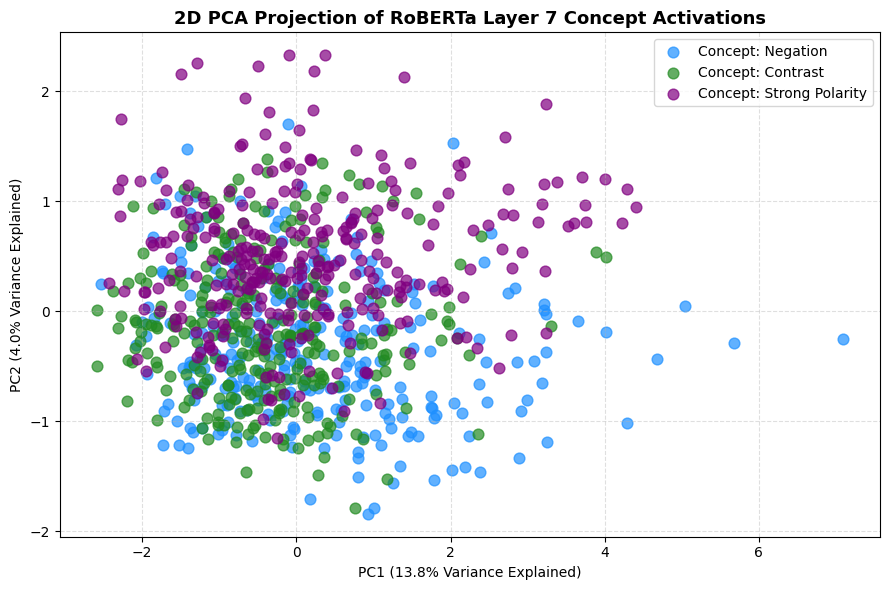

In [17]:
# 2D PCA Visualization of Concept Activation Spaces (Fix)
VIS_LAYER = 7

# 1. Extraction of filtered activations for texts that are positive for a given concept
text_neg = fit_sets["has_negation"][fit_sets["has_negation"]["concept_y"] == 1]["text"].tolist()
text_con = fit_sets["has_contrast"][fit_sets["has_contrast"]["concept_y"] == 1]["text"].tolist()
text_pol = fit_sets["has_strong_polarity"][fit_sets["has_strong_polarity"]["concept_y"] == 1]["text"].tolist()

acts_neg = extract_selected_layers_mean_pool(text_neg, layers=[VIS_LAYER], batch_size=64)[VIS_LAYER]
acts_con = extract_selected_layers_mean_pool(text_con, layers=[VIS_LAYER], batch_size=64)[VIS_LAYER]
acts_pol = extract_selected_layers_mean_pool(text_pol, layers=[VIS_LAYER], batch_size=64)[VIS_LAYER]

# 2. We concatenate and calculate the 2D PCA projections.
all_vis_acts = np.vstack([acts_neg, acts_con, acts_pol])
pca = PCA(n_components=2, random_state=SEED)
pca_proj = pca.fit_transform(all_vis_acts)

n1, n2, n3 = len(acts_neg), len(acts_con), len(acts_pol)
pca_neg = pca_proj[:n1]
pca_con = pca_proj[n1 : n1 + n2]
pca_pol = pca_proj[n1 + n2 :]

# 3. Plotting with alpha transparency to reveal overlaps
plt.figure(figsize=(9, 6))
plt.scatter(pca_neg[:, 0], pca_neg[:, 1], c='dodgerblue', label='Concept: Negation', s=60, alpha=0.7)
plt.scatter(pca_con[:, 0], pca_con[:, 1], c='forestgreen', label='Concept: Contrast', s=60, alpha=0.7)
plt.scatter(pca_pol[:, 0], pca_pol[:, 1], c='purple', label='Concept: Strong Polarity', s=60, alpha=0.7)

plt.title(f"2D PCA Projection of RoBERTa Layer {VIS_LAYER} Concept Activations", fontsize=13, fontweight='bold')
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} Variance Explained)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} Variance Explained)")
plt.legend(frameon=True, fontsize=10)
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

# Class sensitivity

In [18]:
def compute_all_classes_grad_pooled(texts, layer_num, batch_size=32, max_length=128):
    """
    Computes mean-pooled gradients d(logit_c)/d(h_pooled) for all target classes at a specified layer.
    Supports both DistilBERT and RoBERTa model backbones.
    """
    hidden_size = model.config.hidden_size
    n_samples = len(texts)
    grads_by_class = {c: np.zeros((n_samples, hidden_size), dtype=np.float32) for c in CLASS_MAP.values()}

    # Flexible layer extraction for standard transformer backbones
    if hasattr(model, "distilbert"):
        target_module = model.distilbert.transformer.layer[layer_num - 1]
    elif hasattr(model, "roberta"):
        target_module = model.roberta.encoder.layer[layer_num - 1]
    else:
        target_module = model.encoder.layer[layer_num - 1]

    for start in range(0, n_samples, batch_size):
        batch_texts = texts[start : start + batch_size]
        enc = tokenizer(
            batch_texts,
            padding=True,
            truncation=True,
            max_length=max_length,
            return_tensors="pt"
        ).to(device)

        captured = {}
        def hook_fn(module, inp, out):
            h_out = out[0] if isinstance(out, tuple) else out
            h_out.retain_grad()
            captured["h"] = h_out
            return out

        handle = target_module.register_forward_hook(hook_fn)
        outputs = model(**enc)
        handle.remove()

        h_tokens = captured["h"]  # (B, T, hidden_size)
        mask = enc["attention_mask"].unsqueeze(-1).float()  # (B, T, 1)
        valid_tokens = mask.sum(dim=1).clamp(min=1.0)  # (B, 1)

        for c_id in CLASS_MAP.values():
            model.zero_grad()
            if h_tokens.grad is not None:
                h_tokens.grad.zero_()

            score = outputs.logits[:, c_id].sum()
            score.backward(retain_graph=(c_id < max(CLASS_MAP.values())))

            grad_tokens = h_tokens.grad  # (B, T, hidden_size)
            grad_pooled = (grad_tokens * mask).sum(dim=1) / valid_tokens  # (B, hidden_size)
            grads_by_class[c_id][start : start + len(batch_texts)] = grad_pooled.detach().cpu().numpy()

    return grads_by_class

# Generate random control directions (20 per target layer)
rng = np.random.default_rng(42)
N_RANDOM = 20
random_cav_bank = {}
for l in TARGET_LAYERS:
    R = rng.normal(size=(N_RANDOM, model.config.hidden_size)).astype(np.float32)
    R /= np.linalg.norm(R, axis=1, keepdims=True)
    random_cav_bank[l] = R

eval_texts = eval_df["text"].tolist()
concepts = ["has_negation", "has_contrast", "has_strong_polarity"]
sens_rows = []
sample_derivatives = {}  # Cache per-sample derivatives: (layer, class_name, concept) -> np.ndarray

print("Computing class-wise directional derivatives and extended metrics...")
for l in TARGET_LAYERS:
    grads_by_class = compute_all_classes_grad_pooled(eval_texts, l, batch_size=32)

    for c_name, c_id in CLASS_MAP.items():
        G = grads_by_class[c_id]  # (N_eval, hidden_size)

        # Baseline sensitivity using random control directions
        S_rnd = G @ random_cav_bank[l].T  # (N_eval, 20)
        rnd_frac_pos = float((S_rnd > 0).mean())
        rnd_mean_sens = float(S_rnd.mean())

        for concept in concepts:
            c_vals = eval_df[concept].to_numpy()
            v = cavs[concept][l]  # CAV vector (hidden_size,)

            s_cav = G @ v  # Directional derivatives for all eval samples (N_eval,)
            sample_derivatives[(f"L{l:02d}", c_name, concept)] = s_cav

            sens_rows.append({
                "layer": f"L{l:02d}",
                "target_class": f"{c_id}_{c_name}",
                "concept": concept,
                "tcav_frac>0": round(float((s_cav > 0).mean()), 4),
                "rnd_frac>0": round(rnd_frac_pos, 4),
                "mean_sens": round(float(s_cav.mean()), 4),
                "mean_rnd": round(rnd_mean_sens, 4),
                "sens(c=1)": round(float(s_cav[c_vals == 1].mean()), 4) if np.any(c_vals == 1) else 0.0,
                "sens(c=0)": round(float(s_cav[c_vals == 0].mean()), 4) if np.any(c_vals == 0) else 0.0,
            })

sens_all_df = pd.DataFrame(sens_rows)
print("Computation complete. Metric summary table head:")
print(sens_all_df.to_string(index=False))

Computing class-wise directional derivatives and extended metrics...
Computation complete. Metric summary table head:
layer target_class             concept  tcav_frac>0  rnd_frac>0  mean_sens  mean_rnd  sens(c=1)  sens(c=0)
  L03   0_negative        has_negation       0.7403      0.5202     0.0049    0.0002     0.0010     0.0060
  L03   0_negative        has_contrast       0.4993      0.5202    -0.0002    0.0002    -0.0007    -0.0001
  L03   0_negative has_strong_polarity       0.5581      0.5202     0.0003    0.0002     0.0006     0.0003
  L03    1_neutral        has_negation       0.1037      0.4713    -0.0036   -0.0002    -0.0020    -0.0040
  L03    1_neutral        has_contrast       0.6062      0.4713     0.0006   -0.0002     0.0004     0.0006
  L03    1_neutral has_strong_polarity       0.0125      0.4713    -0.0055   -0.0002    -0.0023    -0.0057
  L03   2_positive        has_negation       0.4512      0.5046    -0.0017   -0.0000     0.0007    -0.0023
  L03   2_positive        

# Extended Directional Derivative Analysis

# Top-N Most Positively Sensitive Text Instances

In [19]:
def visualize_top_influences_text(eval_df, derivatives, concept_name, target_class_name, top_n=4):
    """
    Displays the top_n text instances with the highest directional derivative for a concept.
    """
    top_idx = np.argsort(derivatives)[-top_n:][::-1]
    print(f"\n" + "=" * 80)
    print(f"Top {top_n} Text Instances — '{concept_name}' Influence (Target Class: '{target_class_name}')")
    print("=" * 80)
    
    for rank, idx in enumerate(top_idx, 1):
        row = eval_df.iloc[idx]
        text_snippet = row["text"]
        has_concept = row.get(concept_name, "N/A")
        deriv_val = derivatives[idx]
        
        print(f"[{rank}] Derivative: {deriv_val:+.4f} | Concept Present ({concept_name}): {has_concept}")
        print(f"    Text: \"{text_snippet}\"")
        print("-" * 80)

# Example inspection on final target layer (e.g., L06 or last layer in TARGET_LAYERS)
sample_layer = f"L{TARGET_LAYERS[-1]:02d}"
sample_class = "positive" if "positive" in CLASS_MAP else list(CLASS_MAP.keys())[0]

for c_name in concepts:
    derivs = sample_derivatives[(sample_layer, sample_class, c_name)]
    visualize_top_influences_text(eval_df, derivs, c_name, sample_class, top_n=3)


Top 3 Text Instances — 'has_negation' Influence (Target Class: 'positive')
[1] Derivative: -0.0000 | Concept Present (has_negation): 0
    Text: "Benefit from the coupon, that's when you add the stars like bacon, sauce, etc, etc 

ORDER WAS READY 20mins, also the restaurant calls to confirm your online order and calls again when your order is ready."
--------------------------------------------------------------------------------
[2] Derivative: -0.0000 | Concept Present (has_negation): 0
    Text: "Machine learning models are vulnerable to adversarial examples: small changes to images can cause computer vision models to make mistakes such as identifying a school bus as an ostrich. However, it is still an open question whether humans are prone to similar mistakes. Here, we create the first adversarial examples designed to fool humans, by leveraging recent techniques that transfer adversarial examples from computer vision models with known parameters and architecture to other models wi

In [20]:
def visualize_top_influences_text(eval_df, derivatives, concept_name, target_class_name, top_n=4):
    """
    Displays the top_n text instances with the highest directional derivative for a concept.
    """
    top_idx = np.argsort(derivatives)[-top_n:][::-1]
    print(f"\n" + "=" * 80)
    print(f"Top {top_n} Text Instances — '{concept_name}' Influence (Target Class: '{target_class_name}')")
    print("=" * 80)
    
    for rank, idx in enumerate(top_idx, 1):
        row = eval_df.iloc[idx]
        text_snippet = row["text"]
        has_concept = row.get(concept_name, "N/A")
        deriv_val = derivatives[idx]
        
        print(f"[{rank}] Derivative: {deriv_val:+.4f} | Concept Present ({concept_name}): {has_concept}")
        print(f"    Text: \"{text_snippet}\"")
        print("-" * 80)

# Example inspection on final target layer (e.g., L06 or last layer in TARGET_LAYERS)
sample_layer = f"L{TARGET_LAYERS[-1]:02d}"
sample_class = "positive" if "positive" in CLASS_MAP else list(CLASS_MAP.keys())[0]

for c_name in concepts:
    derivs = sample_derivatives[(sample_layer, sample_class, c_name)]
    visualize_top_influences_text(eval_df, derivs, c_name, sample_class, top_n=3)


Top 3 Text Instances — 'has_negation' Influence (Target Class: 'positive')
[1] Derivative: -0.0000 | Concept Present (has_negation): 0
    Text: "Benefit from the coupon, that's when you add the stars like bacon, sauce, etc, etc 

ORDER WAS READY 20mins, also the restaurant calls to confirm your online order and calls again when your order is ready."
--------------------------------------------------------------------------------
[2] Derivative: -0.0000 | Concept Present (has_negation): 0
    Text: "Machine learning models are vulnerable to adversarial examples: small changes to images can cause computer vision models to make mistakes such as identifying a school bus as an ostrich. However, it is still an open question whether humans are prone to similar mistakes. Here, we create the first adversarial examples designed to fool humans, by leveraging recent techniques that transfer adversarial examples from computer vision models with known parameters and architecture to other models wi

# Directional Derivative Distributions & Concept Importance

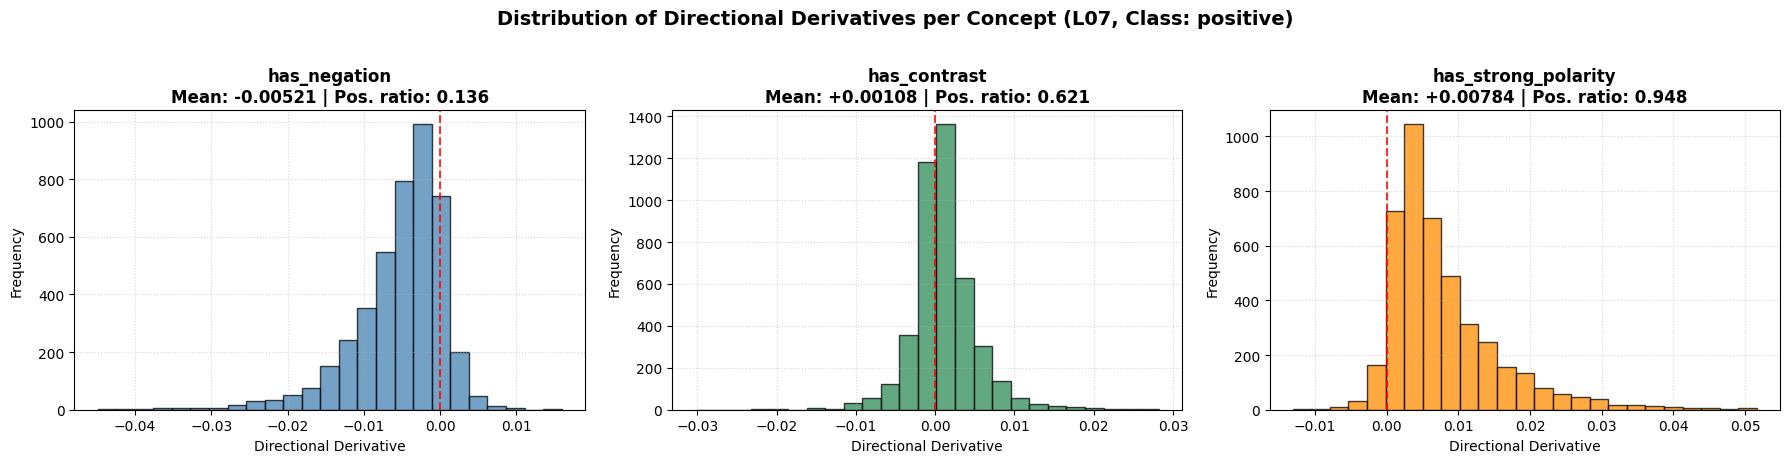

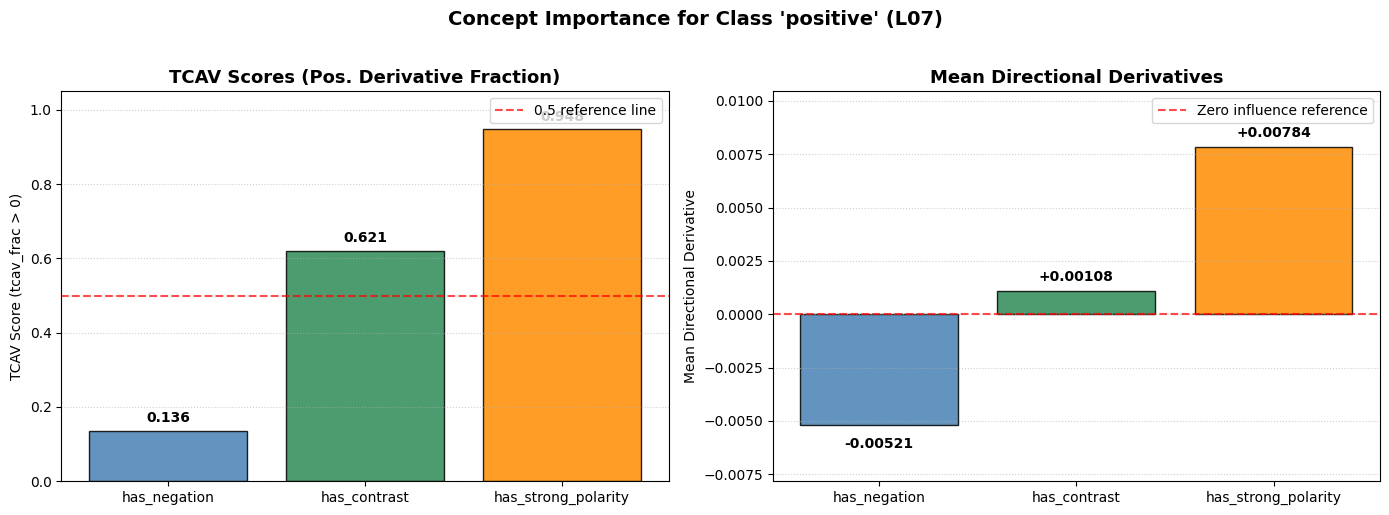

In [23]:
# Select target layer and class for detailed distribution plots
target_layer_str = f"L{TARGET_LAYERS[1]:02d}"
target_cls_name = "positive" if "positive" in CLASS_MAP else list(CLASS_MAP.keys())[0]

derivs_list = [sample_derivatives[(target_layer_str, target_cls_name, c)] for c in concepts]
tcav_scores = [float((d > 0).mean()) for d in derivs_list]
mean_derivs = [float(np.mean(d)) for d in derivs_list]
colors = ['steelblue', 'seagreen', 'darkorange']

# 1. Distribution of directional derivatives per concept
fig, axes = plt.subplots(1, len(concepts), figsize=(6 * len(concepts), 4.5))
if len(concepts) == 1:
    axes = [axes]

for ax, concept, derivs, color in zip(axes, concepts, derivs_list, colors):
    ax.hist(derivs, bins=25, alpha=0.75, color=color, edgecolor='black')
    ax.axvline(0, color='red', linestyle='--', alpha=0.8, linewidth=1.5)
    mean_val = np.mean(derivs)
    pos_ratio = np.mean(derivs > 0)
    ax.set_title(f"{concept}\nMean: {mean_val:+.3g} | Pos. ratio: {pos_ratio:.3f}", fontsize=12, fontweight='bold')
    ax.set_xlabel("Directional Derivative")
    ax.set_ylabel("Frequency")
    ax.grid(True, linestyle=':', alpha=0.5)

plt.suptitle(f"Distribution of Directional Derivatives per Concept ({target_layer_str}, Class: {target_cls_name})", 
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# 2. Side-by-side Bar plots for TCAV scores and Mean Derivatives (Lab 4.2 plot style)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left plot: TCAV Scores (Fraction > 0)
bars1 = axes[0].bar(concepts, tcav_scores, color=colors, alpha=0.85, edgecolor='black')
axes[0].axhline(0.5, color='red', linestyle='--', alpha=0.7, label='0.5 reference line')
axes[0].set_ylim(0, 1.05)
axes[0].set_title("TCAV Scores (Pos. Derivative Fraction)", fontsize=13, fontweight='bold')
axes[0].set_ylabel("TCAV Score (tcav_frac > 0)")
axes[0].legend(loc='upper right')
axes[0].grid(axis='y', linestyle=':', alpha=0.6)

for bar, score in zip(bars1, tcav_scores):
    axes[0].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.015,
                 f'{score:.3f}', ha='center', va='bottom', fontweight='bold')

# Right plot: Mean Directional Derivatives
bars2 = axes[1].bar(concepts, mean_derivs, color=colors, alpha=0.85, edgecolor='black')
axes[1].axhline(0, color='red', linestyle='--', alpha=0.7, label='Zero influence reference')
axes[1].set_title("Mean Directional Derivatives", fontsize=13, fontweight='bold')
axes[1].set_ylabel("Mean Directional Derivative")
axes[1].legend(loc='upper right')
axes[1].grid(axis='y', linestyle=':', alpha=0.6)

for bar, val in zip(bars2, mean_derivs):
    axes[1].annotate(f'{val:+.3g}',
                     xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
                     xytext=(0, 5 if val >= 0 else -8), textcoords='offset points',
                     ha='center', va='bottom' if val >= 0 else 'top', fontweight='bold')

axes[1].margins(y=0.2)
plt.suptitle(f"Concept Importance for Class '{target_cls_name}' ({target_layer_str})", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# Input Edits

In [22]:
model.eval()
id2label = model.config.id2label

input_edits = [
    {
        "id": 4148,
        "concept": "has_negation",
        "edit_type": "replace_neg_clause",
        "orig_text": (
            "We tried a new place. Not worth the price, wait, or probable"
            " health risks."
        ),
        "edited_text": (
            "We tried a new place. It is worth the price, wait, and probable"
            " health risks."
        ),
        "expected": "up_pos / down_neg",
    },
    {
        "id": 4335,
        "concept": "has_negation",
        "edit_type": "remove_not",
        "orig_text": (
            "A minute later, the TV will go up several channels like it's"
            " possessed. Which is not good."
        ),
        "edited_text": (
            "A minute later, the TV will go up several channels like it's"
            " possessed. Which is good."
        ),
        "expected": "up_pos / down_neg",
    },
    {
        "id": 409,
        "concept": "has_negation",
        "edit_type": "neither_nor -> both_and",
        "orig_text": (
            "Alas, neither she nor I were able to find a new pair in my size."
        ),
        "edited_text": (
            "Alas, both she and I were able to find a new pair in my size."
        ),
        "expected": "down_neg / shift_neu_or_pos",
    },
    {
        "id": 3705,
        "concept": "has_contrast",
        "edit_type": "but -> and",
        "orig_text": (
            "The place was quaint but the waiter was rude and the food was"
            " terrible."
        ),
        "edited_text": (
            "The place was quaint and the waiter was rude and the food was"
            " terrible."
        ),
        "expected": "smaller_contrast (neg stays high)",
    },
    {
        "id": 163,
        "concept": "has_contrast",
        "edit_type": "drop_although",
        "orig_text": (
            "Although they are branded as a Mitsubishi Dealership, they carry"
            " high end used cars and act as a used car dealership on the side."
        ),
        "edited_text": (
            "They are branded as a Mitsubishi Dealership, they carry high end"
            " used cars and act as a used car dealership on the side."
        ),
        "expected": "shift_from_neu_or_d_logit",
    },
    {
        "id": 4227,
        "concept": "has_contrast",
        "edit_type": "but -> and",
        "orig_text": "A little dry and chewy, but that's just to my taste!",
        "edited_text": "A little dry and chewy, and that's just to my taste!",
        "expected": "change_polarity_balance",
    },
    {
        "id": 3912,
        "concept": "has_strong_polarity",
        "edit_type": "awesome -> ok",
        "orig_text": (
            "If you like high prices and crowds, Container Park is awesome."
        ),
        "edited_text": "If you like high prices and crowds, Container Park is ok.",
        "expected": "shift_neu / down_pos",
    },
    {
        "id": 3966,
        "concept": "has_strong_polarity",
        "edit_type": "amazing -> decent",
        "orig_text": (
            "Is it even fair to expect a fish place would have amazing wings?"
        ),
        "edited_text": (
            "Is it even fair to expect a fish place would have decent wings?"
        ),
        "expected": "shift_neu / less_extreme_logit",
    },
    {
        "id": 3957,
        "concept": "has_strong_polarity",
        "edit_type": "excellent -> good",
        "orig_text": (
            "It was excellent and huge portions I had forgotten I had spent the"
            " night on the toilet."
        ),
        "edited_text": (
            "It was good and huge portions I had forgotten I had spent the"
            " night on the toilet."
        ),
        "expected": "down_pos / shift_neg",
    },
]


def predict_logits_and_probs(texts, batch_size=32, max_length=128):
  all_logits, all_probs = [], []
  with torch.no_grad():
    for start in range(0, len(texts), batch_size):
      enc = tokenizer(
          texts[start : start + batch_size],
          padding=True,
          truncation=True,
          max_length=max_length,
          return_tensors="pt",
      ).to(device)
      logits = model(**enc).logits
      probs = torch.softmax(logits, dim=-1)
      all_logits.append(logits.cpu())
      all_probs.append(probs.cpu())
  return torch.cat(all_logits, dim=0), torch.cat(all_probs, dim=0)


orig_logits, orig_probs = predict_logits_and_probs(
    [x["orig_text"] for x in input_edits]
)
edit_logits, edit_probs = predict_logits_and_probs(
    [x["edited_text"] for x in input_edits]
)

rows = []
for i, item in enumerate(input_edits):
  l0, l1 = orig_logits[i], edit_logits[i]
  p0, p1 = orig_probs[i], edit_probs[i]

  pred0 = id2label[int(torch.argmax(l0).item())]
  pred1 = id2label[int(torch.argmax(l1).item())]

  rows.append({
      "id": item["id"],
      "concept": item["concept"],
      "edit": item["edit_type"],
      "expected": item["expected"],
      "pred": f"{pred0}->{pred1}",
      "d_neg": round(float((l1[0] - l0[0]).item()), 3),
      "d_neu": round(float((l1[1] - l0[1]).item()), 3),
      "d_pos": round(float((l1[2] - l0[2]).item()), 3),
  })

edits_res_df = pd.DataFrame(rows)
print(edits_res_df.to_string(index=False))

  id             concept                    edit                          expected               pred  d_neg  d_neu  d_pos
4148        has_negation      replace_neg_clause                 up_pos / down_neg  negative->neutral -2.468  0.292  2.067
4335        has_negation              remove_not                 up_pos / down_neg negative->positive -3.645  0.184  3.613
 409        has_negation neither_nor -> both_and       down_neg / shift_neu_or_pos  neutral->positive -3.590  0.438  3.321
3705        has_contrast              but -> and smaller_contrast (neg stays high) negative->negative  0.118 -0.127 -0.015
 163        has_contrast           drop_although         shift_from_neu_or_d_logit   neutral->neutral  0.158  0.012 -0.050
4227        has_contrast              but -> and           change_polarity_balance   neutral->neutral  0.384 -0.147 -0.316
3912 has_strong_polarity           awesome -> ok              shift_neu / down_pos  positive->neutral  1.485  1.076 -2.870
3966 has_strong_